# CRNN — Test Results and Prediction Plots

This notebook visualizes **saved CRNN test predictions and evaluation results** in `output/crnn_initial/`. It does not retrain models or modify model checkpoints.

It includes:
- automatic repository/results-folder discovery from common Jupyter launch locations;
- patient-wise and horizon-wise test metrics;
- actual-versus-predicted glucose traces for available patients and horizons;
- prediction scatter and residual diagnostics;
- recomputed MAE, RMSE, and MARD from saved test predictions;
- reference-aligned Clarke Error Grid (CEG) zone summaries;
- export of prediction traces to `output/crnn_initial/plots/`.

Run the notebook cells from top to bottom. The results directory must contain the project's saved CRNN prediction CSVs.


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository/results directory from common notebook launch locations.
def find_prediction_root(start=None):
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    bases = [start, *start.parents]

    # First check the current directory and its parents (normal repo launch).
    for base in bases:
        for candidate in (base / "output" / "crnn_initial",
                          base / "CGM-Forecasting-Research" / "output" / "crnn_initial"):
            if candidate.is_dir() and list(candidate.glob("patient_*/horizon_*min/test_predictions.csv")):
                return candidate.parent.parent, candidate

        # If Jupyter was launched from output/crnn_initial itself.
        if base.name == "crnn_initial" and list(base.glob("patient_*/horizon_*min/test_predictions.csv")):
            return base.parent.parent, base

    # Search a few levels below the launch directory; useful when launched from
    # a workspace folder such as "new cgm research" containing the repository.
    search_roots = [start]
    search_roots.extend(p for p in bases[1:3] if p.exists())
    seen = set()
    for search_root in search_roots:
        try:
            candidates = search_root.glob("**/output/crnn_initial")
            for candidate in candidates:
                resolved = candidate.resolve()
                if resolved in seen:
                    continue
                seen.add(resolved)
                if list(candidate.glob("patient_*/horizon_*min/test_predictions.csv")):
                    return candidate.parent.parent, candidate
        except (PermissionError, OSError):
            continue

    raise FileNotFoundError(
        "Could not find saved CRNN predictions. Expected a folder containing "
        "output/crnn_initial/patient_<ID>/horizon_<N>min/test_predictions.csv. "
        "Extract the CGM-Forecasting-Research project ZIP, then run this notebook "
        "from the repository or a folder inside it."
    )

ROOT, PRED_ROOT = find_prediction_root()
FIG_ROOT = PRED_ROOT / "plots"
FIG_ROOT.mkdir(parents=True, exist_ok=True)

print("Repository root:", ROOT.resolve())
print("CRNN results:", PRED_ROOT.resolve())
print("Figures will be saved to:", FIG_ROOT.resolve())


Repository root: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research
CRNN results: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial
Figures will be saved to: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots


In [13]:
prediction_files = sorted(PRED_ROOT.glob("patient_*/horizon_*min/test_predictions.csv"))
if not prediction_files:
    raise FileNotFoundError(
        f"No saved test prediction files found under {PRED_ROOT}/patient_*/horizon_*min/"
    )

def parse_prediction_path(path):
    patient = path.parent.parent.name.replace("patient_", "")
    horizon = path.parent.name.replace("horizon_", "").replace("min", "")
    return int(patient), int(horizon)

available = pd.DataFrame(
    [{"patient": parse_prediction_path(p)[0],
      "horizon_minutes": parse_prediction_path(p)[1],
      "file": str(p)} for p in prediction_files]
).sort_values(["horizon_minutes", "patient"]).reset_index(drop=True)

print(f"Found {len(prediction_files)} prediction files.")
print("Patients:", sorted(available.patient.unique().tolist()))
print("Horizons (minutes):", sorted(available.horizon_minutes.unique().tolist()))
display(available[["patient", "horizon_minutes"]])


Found 24 prediction files.
Patients: [540, 544, 552, 559, 563, 567, 570, 575, 584, 588, 591, 596]
Horizons (minutes): [30, 60]


,patient,horizon_minutes
0,540,30
1,544,30
2,552,30
3,559,30
4,563,30
5,567,30
6,570,30
7,575,30
8,584,30
9,588,30


In [14]:
# Load existing metrics if present. Prefer the reference-aligned table for CEG plots.
def read_csv_if_exists(path):
    return pd.read_csv(path) if path.exists() else None

metrics_30 = read_csv_if_exists(PRED_ROOT / "crnn_30min_test_metrics.csv")
metrics_60 = read_csv_if_exists(PRED_ROOT / "crnn_60min_test_metrics.csv")
clinical = read_csv_if_exists(PRED_ROOT / "clinical_metrics_reference_aligned.csv")

metric_frames = [df for df in [metrics_30, metrics_60] if df is not None and not df.empty]
if metric_frames:
    metrics = pd.concat(metric_frames, ignore_index=True)
    # Avoid duplicate patient/horizon rows if the same horizon appears in more than one file.
    if {"patient", "horizon_minutes"}.issubset(metrics.columns):
        metrics = metrics.drop_duplicates(["patient", "horizon_minutes"], keep="last")
    display(metrics.sort_values(["horizon_minutes", "patient"]).reset_index(drop=True))
else:
    metrics = pd.DataFrame()
    print("No summary metric CSVs found; metrics will be computed from prediction files where possible.")

if clinical is not None:
    print("Reference-aligned clinical metrics:", clinical.shape)
else:
    print("Reference-aligned clinical metrics CSV not found; CEG distribution plot will be skipped.")


,n,MAE_mg_dL,RMSE_mg_dL,MARD_percent,patient,horizon_minutes,best_epoch,best_validation_MAE_delta,checkpoint,n_train,n_validation
0,2434,15.329533,21.245169,10.346180,540,30,25,13.878558,output/crnn_initial/patient_540/horizon_30min/...,8681,1547
1,2484,11.928751,17.015271,7.904002,544,30,6,11.106378,output/crnn_initial/patient_544/horizon_30min/...,8504,1449
2,1882,13.165240,17.969983,10.102339,552,30,9,16.151343,output/crnn_initial/patient_552/horizon_30min/...,6141,1014
3,2166,12.890421,19.077930,7.927961,559,30,10,15.555965,output/crnn_initial/patient_559/horizon_30min/...,8056,1446
4,2454,13.059533,18.572144,8.114950,563,30,10,12.157591,output/crnn_initial/patient_563/horizon_30min/...,9812,1645
5,1866,14.244738,20.856636,10.013870,567,30,19,14.602674,output/crnn_initial/patient_567/horizon_30min/...,7219,1301
6,2455,11.040627,15.783016,5.810769,570,30,10,12.137636,output/crnn_initial/patient_570/horizon_30min/...,8813,1532
7,2286,13.995434,22.648280,10.090054,575,30,15,12.523532,output/crnn_initial/patient_575/horizon_30min/...,8296,1452
8,2201,14.927016,20.588717,10.043901,584,30,39,22.392951,output/crnn_initial/patient_584/horizon_30min/...,8954,1442
9,2704,14.006865,19.294775,8.278152,588,30,10,16.236347,output/crnn_initial/patient_588/horizon_30min/...,10475,1838


Reference-aligned clinical metrics: (24, 15)


## 1. Patient-wise test performance

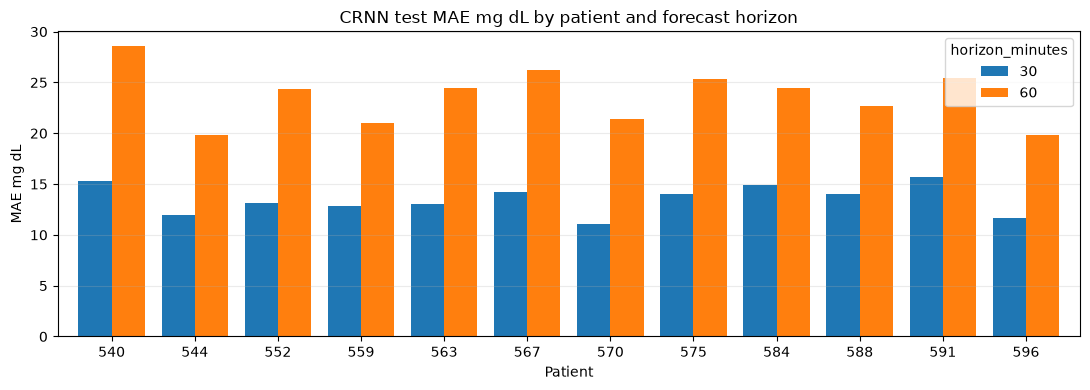

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/patientwise_MAE_mg_dL.png


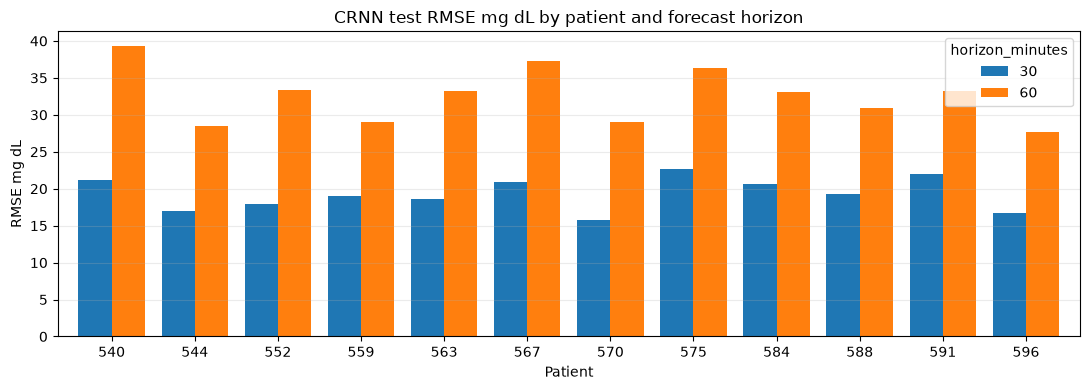

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/patientwise_RMSE_mg_dL.png


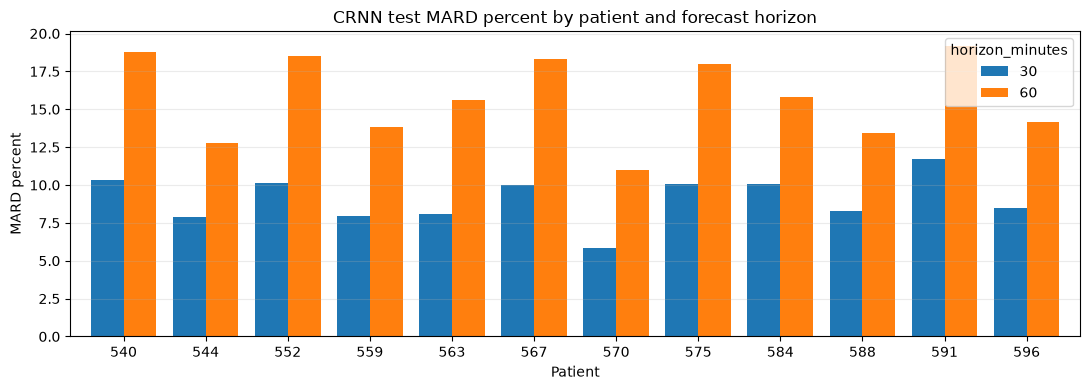

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/patientwise_MARD_percent.png


In [15]:
if not metrics.empty and {"patient", "horizon_minutes"}.issubset(metrics.columns):
    for col in ["MAE_mg_dL", "RMSE_mg_dL", "MARD_percent"]:
        if col in metrics.columns:
            pivot = metrics.pivot_table(index="patient", columns="horizon_minutes", values=col, aggfunc="mean")
            ax = pivot.plot(kind="bar", figsize=(11, 4), width=0.8)
            ax.set_title(f"CRNN test {col.replace('_', ' ')} by patient and forecast horizon")
            ax.set_xlabel("Patient")
            ax.set_ylabel(col.replace("_", " "))
            ax.grid(axis="y", alpha=0.25)
            plt.xticks(rotation=0)
            plt.tight_layout()
            out = FIG_ROOT / f"patientwise_{col}.png"
            plt.savefig(out, dpi=160, bbox_inches="tight")
            plt.show()
            print("Saved:", out)
else:
    print("Patient-wise summary plot skipped because metric summary columns are unavailable.")


## 2. Actual vs predicted glucose

The next cell draws a time-ordered view of the saved test predictions. Edit `PLOT_PATIENT` to choose a patient, and `MAX_POINTS` to control how much of the test set is shown. The timestamp used is `target_timestamp` when available; otherwise, row order is used.

In [16]:
PLOT_PATIENT = int(sorted(available.patient.unique())[0])
MAX_POINTS = 500  # use None to plot every test prediction


Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/prediction_trace_patient_540_30min.png


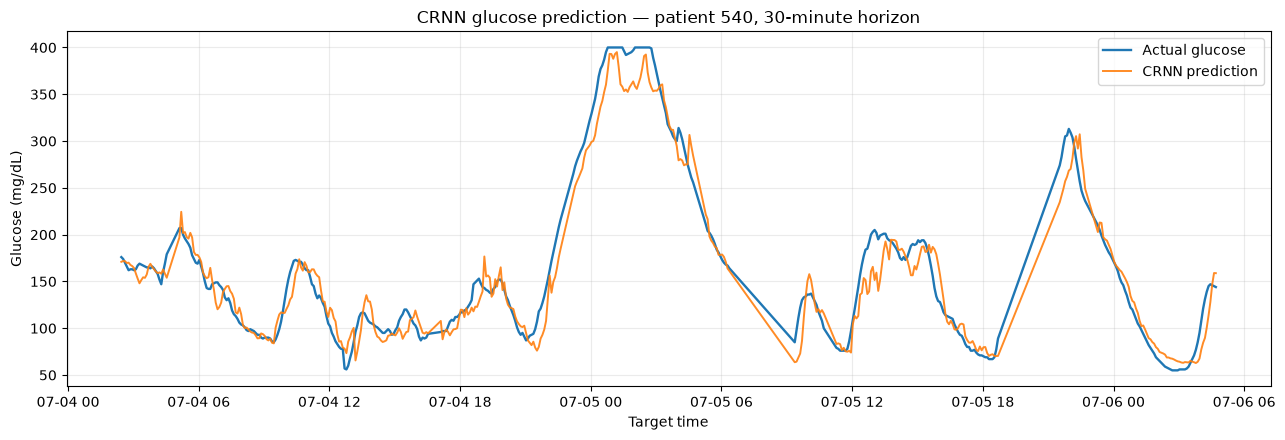

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/prediction_trace_patient_540_60min.png


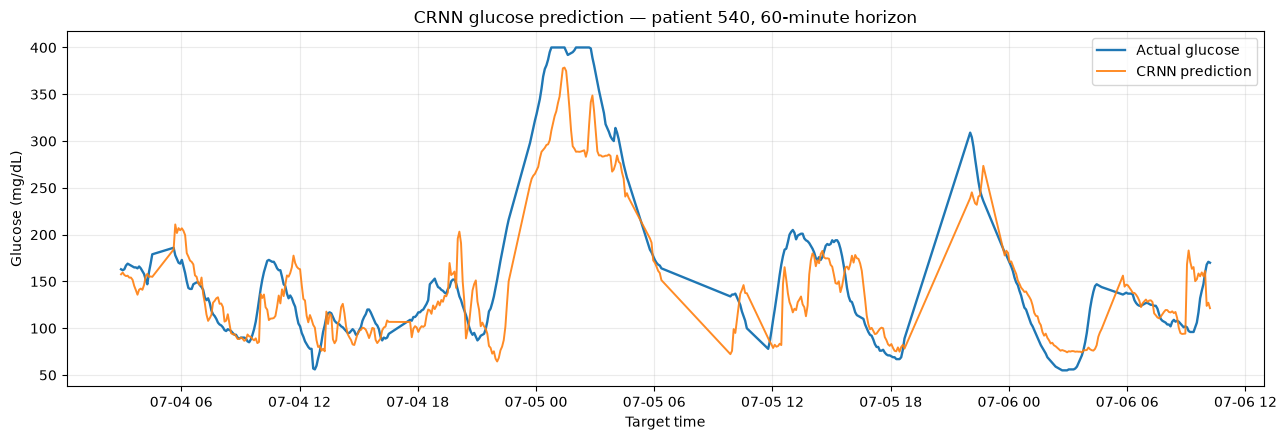

In [17]:
def load_predictions(patient, horizon):
    matches = [Path(p) for p in available.loc[
        (available.patient == int(patient)) & (available.horizon_minutes == int(horizon)), "file"
    ]]
    if not matches:
        raise FileNotFoundError(f"No prediction CSV for patient {patient}, horizon {horizon} min.")
    df = pd.read_csv(matches[0])
    required = {"target_glucose", "predicted_glucose"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{matches[0].name} is missing required columns: {sorted(missing)}")
    if "target_timestamp" in df.columns:
        df["target_timestamp"] = pd.to_datetime(df["target_timestamp"], errors="coerce")
        df = df.sort_values("target_timestamp", kind="stable")
    df = df.reset_index(drop=True)
    return df

def plot_prediction_trace(patient, horizon, max_points=MAX_POINTS, save=True):
    df = load_predictions(patient, horizon)
    shown = df if max_points is None else df.iloc[:int(max_points)].copy()
    x = shown["target_timestamp"] if "target_timestamp" in shown and shown["target_timestamp"].notna().any() else np.arange(len(shown))
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(x, shown["target_glucose"], label="Actual glucose", linewidth=1.7)
    ax.plot(x, shown["predicted_glucose"], label="CRNN prediction", linewidth=1.4, alpha=0.9)
    ax.set_title(f"CRNN glucose prediction — patient {patient}, {horizon}-minute horizon")
    ax.set_xlabel("Target time" if hasattr(x, "dtype") and "datetime" in str(x.dtype) else "Test sample")
    ax.set_ylabel("Glucose (mg/dL)")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    if save:
        out = FIG_ROOT / f"prediction_trace_patient_{patient}_{horizon}min.png"
        fig.savefig(out, dpi=160, bbox_inches="tight")
        print("Saved:", out)
    plt.show()
    return df

for horizon in sorted(available.horizon_minutes.unique()):
    if ((available.patient == PLOT_PATIENT) & (available.horizon_minutes == horizon)).any():
        _ = plot_prediction_trace(PLOT_PATIENT, horizon)


## 3. Prediction scatter and residual distribution

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/diagnostics_patient_540_30min.png


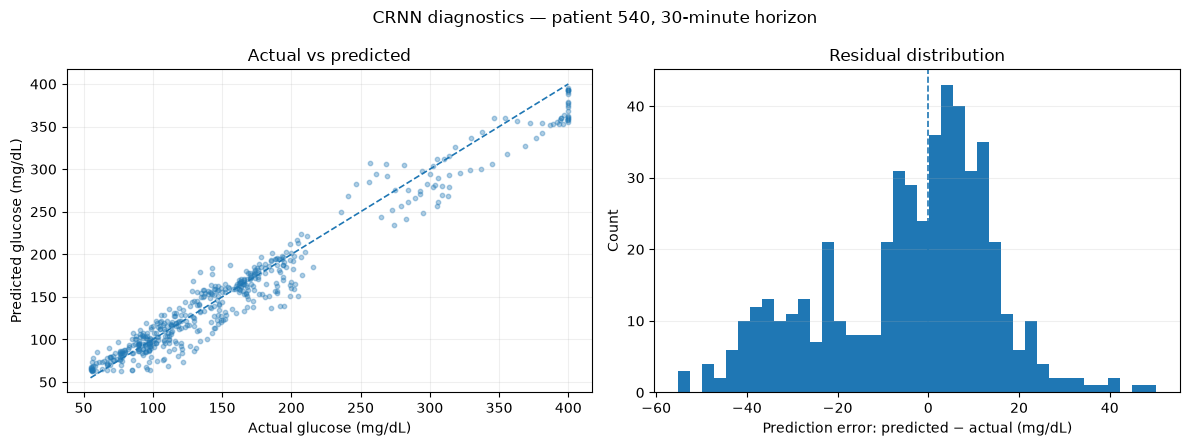

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/diagnostics_patient_540_60min.png


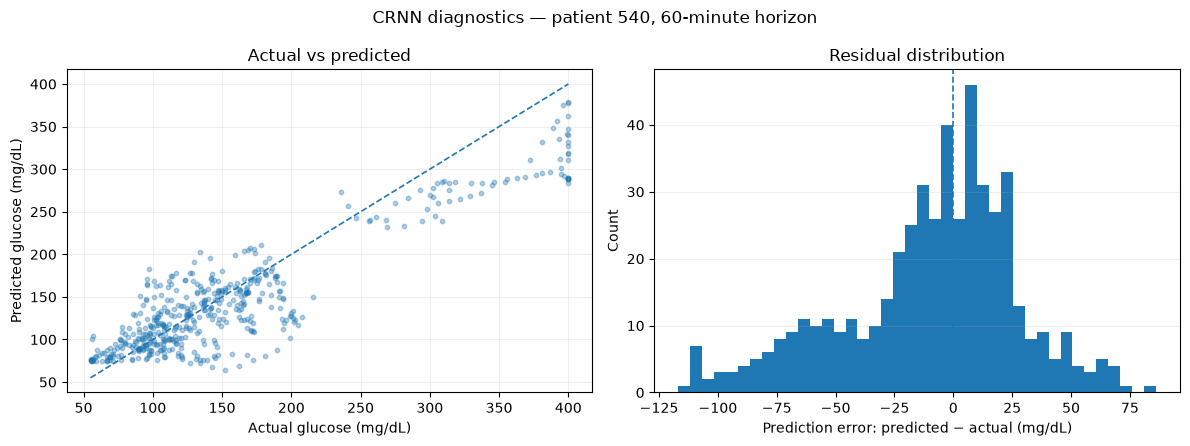

In [18]:
def plot_prediction_diagnostics(patient, horizon, max_points=MAX_POINTS, save=True):
    df = load_predictions(patient, horizon)
    if max_points is not None:
        df = df.iloc[:int(max_points)].copy()
    actual = pd.to_numeric(df["target_glucose"], errors="coerce")
    pred = pd.to_numeric(df["predicted_glucose"], errors="coerce")
    valid = actual.notna() & pred.notna()
    actual, pred = actual[valid], pred[valid]
    residual = pred - actual
    if len(actual) == 0:
        print("No valid numeric predictions.")
        return
    lo = float(min(actual.min(), pred.min()))
    hi = float(max(actual.max(), pred.max()))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(actual, pred, s=10, alpha=0.35)
    axes[0].plot([lo, hi], [lo, hi], linestyle="--", linewidth=1.2)
    axes[0].set_xlabel("Actual glucose (mg/dL)")
    axes[0].set_ylabel("Predicted glucose (mg/dL)")
    axes[0].set_title("Actual vs predicted")
    axes[0].grid(alpha=0.2)
    axes[1].hist(residual, bins=40)
    axes[1].axvline(0, linestyle="--", linewidth=1.2)
    axes[1].set_xlabel("Prediction error: predicted − actual (mg/dL)")
    axes[1].set_ylabel("Count")
    axes[1].set_title("Residual distribution")
    axes[1].grid(axis="y", alpha=0.2)
    fig.suptitle(f"CRNN diagnostics — patient {patient}, {horizon}-minute horizon")
    fig.tight_layout()
    if save:
        out = FIG_ROOT / f"diagnostics_patient_{patient}_{horizon}min.png"
        fig.savefig(out, dpi=160, bbox_inches="tight")
        print("Saved:", out)
    plt.show()

for horizon in sorted(available.horizon_minutes.unique()):
    if ((available.patient == PLOT_PATIENT) & (available.horizon_minutes == horizon)).any():
        plot_prediction_diagnostics(PLOT_PATIENT, horizon)


## 4. Recompute simple metrics from saved prediction CSVs

In [19]:
rows = []
for rec in available.itertuples(index=False):
    df = pd.read_csv(rec.file)
    if not {"target_glucose", "predicted_glucose"}.issubset(df.columns):
        continue
    actual = pd.to_numeric(df["target_glucose"], errors="coerce").to_numpy()
    pred = pd.to_numeric(df["predicted_glucose"], errors="coerce").to_numpy()
    mask = np.isfinite(actual) & np.isfinite(pred)
    actual, pred = actual[mask], pred[mask]
    if not len(actual):
        continue
    mae = np.mean(np.abs(pred - actual))
    rmse = np.sqrt(np.mean((pred - actual) ** 2))
    nonzero = np.abs(actual) > 1e-8
    mard = np.mean(np.abs((pred[nonzero] - actual[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    rows.append({"patient": rec.patient, "horizon_minutes": rec.horizon_minutes,
                 "n": len(actual), "MAE_mg_dL": mae, "RMSE_mg_dL": rmse,
                 "MARD_percent": mard})
recomputed = pd.DataFrame(rows).sort_values(["horizon_minutes", "patient"])
display(recomputed.round(3))
recomputed.to_csv(FIG_ROOT / "crnn_metrics_recomputed_from_predictions.csv", index=False)
print("Saved:", FIG_ROOT / "crnn_metrics_recomputed_from_predictions.csv")


,patient,horizon_minutes,n,MAE_mg_dL,RMSE_mg_dL,MARD_percent
0,540,30,2434,15.330,21.245,10.346
1,544,30,2484,11.929,17.015,7.904
2,552,30,1882,13.165,17.970,10.102
3,559,30,2166,12.890,19.078,7.928
4,563,30,2454,13.060,18.572,8.115
5,567,30,1866,14.245,20.857,10.014
6,570,30,2455,11.041,15.783,5.811
7,575,30,2286,13.995,22.648,10.090
8,584,30,2201,14.927,20.589,10.044
9,588,30,2704,14.007,19.295,8.278


Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/crnn_metrics_recomputed_from_predictions.csv


## 5. Clarke Error Grid zone distribution

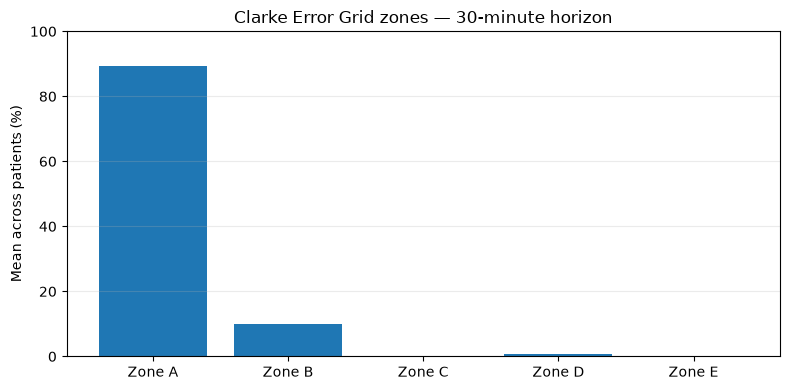

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/clarke_error_grid_zone_distribution_30min.png


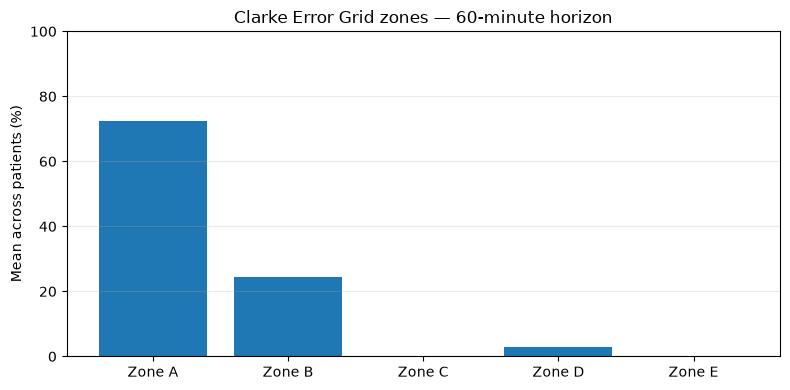

Saved: /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots/clarke_error_grid_zone_distribution_60min.png


In [20]:
if clinical is not None:
    zone_cols = [c for c in ["CEG_A_percent", "CEG_B_percent", "CEG_C_percent", "CEG_D_percent", "CEG_E_percent"] if c in clinical.columns]
    if zone_cols and {"patient", "horizon_minutes"}.issubset(clinical.columns):
        for horizon, part in clinical.groupby("horizon_minutes"):
            zone_means = part[zone_cols].mean()
            fig, ax = plt.subplots(figsize=(8, 4))
            labels = [c.replace("CEG_", "Zone ").replace("_percent", "") for c in zone_cols]
            ax.bar(labels, zone_means.values)
            ax.set_ylim(0, 100)
            ax.set_ylabel("Mean across patients (%)")
            ax.set_title(f"Clarke Error Grid zones — {horizon}-minute horizon")
            ax.grid(axis="y", alpha=0.25)
            fig.tight_layout()
            out = FIG_ROOT / f"clarke_error_grid_zone_distribution_{horizon}min.png"
            fig.savefig(out, dpi=160, bbox_inches="tight")
            plt.show()
            print("Saved:", out)
    else:
        print("CEG zone columns or grouping columns are missing; skipped.")
else:
    print("No clinical_metrics_reference_aligned.csv available; skipped.")


## 6. Export prediction plots for every patient and horizon

This generates one actual-vs-predicted trace for every saved prediction file. It can take a little time if there are many files. Files are saved to `output/crnn_initial/plots_for_professor/`.

In [21]:
EXPORT_ALL_PREDICTION_TRACES = True
if EXPORT_ALL_PREDICTION_TRACES:
    exported = 0
    for rec in available.itertuples(index=False):
        df = load_predictions(rec.patient, rec.horizon_minutes)
        shown = df if MAX_POINTS is None else df.iloc[:int(MAX_POINTS)].copy()
        x = shown["target_timestamp"] if "target_timestamp" in shown and shown["target_timestamp"].notna().any() else np.arange(len(shown))
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(x, shown["target_glucose"], label="Actual", linewidth=1.5)
        ax.plot(x, shown["predicted_glucose"], label="CRNN prediction", linewidth=1.2)
        ax.set_title(f"CRNN — patient {rec.patient}, horizon {rec.horizon_minutes} min")
        ax.set_xlabel("Target time" if "target_timestamp" in shown and shown["target_timestamp"].notna().any() else "Test sample")
        ax.set_ylabel("Glucose (mg/dL)")
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        out = FIG_ROOT / f"prediction_trace_patient_{rec.patient}_{rec.horizon_minutes}min.png"
        fig.savefig(out, dpi=150, bbox_inches="tight")
        plt.close(fig)
        exported += 1
    print(f"Exported {exported} prediction traces to {FIG_ROOT}")


Exported 24 prediction traces to /Users/sulabhyadav/Desktop/new cgm research/CGM-Forecasting-Research/output/crnn_initial/plots


## Notes on interpretation

- Forecast horizons and patient IDs are read from the saved folder names.
- The notebook plots existing held-out test predictions; it does not fit or alter the CRNN model.
- The time-series plot uses the first `MAX_POINTS` rows after timestamp sorting. Set `MAX_POINTS = None` to show the entire test set.
- CEG percentages are shown only when the provided reference-aligned clinical metrics file is present.
- A plotted forecast is not evidence of clinical readiness. Clinical safety claims require careful validation, transparent patient-wise reporting, and an appropriate evaluation protocol.
